In [1]:
import os
from typing import Optional

from dotenv import load_dotenv
from langchain_core.utils.utils import secret_from_env
from langchain_openai import ChatOpenAI
from pydantic import Field, SecretStr

load_dotenv()

class ChatOpenRouter(ChatOpenAI):
    openai_api_key: Optional[SecretStr] = Field(
        alias="api_key", default_factory=secret_from_env("OPENROUTER_API_KEY", default=None)
    )
    @property
    def lc_secrets(self) -> dict[str, str]:
        return {"openai_api_key": "OPENROUTER_API_KEY"}

    def __init__(self,
                 openai_api_key: Optional[str] = None,
                 **kwargs):
        openai_api_key = openai_api_key or os.environ.get("OPENROUTER_API_KEY")
        super().__init__(base_url="https://openrouter.ai/api/v1", openai_api_key=openai_api_key, **kwargs)


model = ChatOpenRouter(model_name="google/gemini-2.5-flash", temperature=0.0)

/home/chen/GNPS_SIM/agent/db_form_agent_system/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
import pandas as pd

df = pd.read_csv("/home/chen/GNPS_SIM/agent/db_form_agent_system/notebooks/quantified_metabolites.csv")

# get 100 rows with 80% endogenous
df_endogenous = df[df['Endogenous']=='Yes'].sample(n=27, random_state=42)
df_non_endogenous = df[df['Endogenous']=='No'].sample(n=3, random_state=42)
df_sampled = pd.concat([df_endogenous, df_non_endogenous]).reset_index(drop=True)

In [8]:
df_sampled

,Accession,Name,Description,Chemical_Formula,Average_Molecular_Weight,Monisotopic_Molecular_Weight,IUPAC_Name,Traditional_IUPAC,CAS_Registry_Number,SMILES,InChI,InChIKey,Synonyms,Ontology,Endogenous
0,HMDB0007458,"DG(20:3(5Z,8Z,11Z)/20:3(5Z,8Z,11Z)/0:0)","DG(20:3(5Z,8Z,11Z)/20:3(5Z,8Z,11Z)/0:0) is a d...",C43H72O5,669.0288,668.537975,"(2S)-1-hydroxy-3-[(5Z,8Z,11Z)-icosa-5,8,11-tri...","1,2-dimeadoyl-rac-glycerol",NaN,[H][C@](CO)(COC(=O)CCC\C=C/C\C=C/C\C=C/CCCCCCC...,InChI=1S/C43H72O5/c1-3-5-7-9-11-13-15-17-19-21...,VIGULOPHPJPIAO-XIUQCZDVSA-N,"1,2-Dimeadoyl-rac-glycerol; DAG(20:3/20:3); DA...",\n,Yes
1,HMDB0010418,"TG(16:0/16:0/22:6(4Z,7Z,10Z,13Z,16Z,19Z))","TG(16:0/16:0/22:6(4Z,7Z,10Z,13Z,16Z,19Z))[iso3...",C57H98O6,879.4050,878.736341,"(2S)-2,3-bis(hexadecanoyloxy)propyl (4Z,7Z,10Z...","(2S)-2,3-bis(hexadecanoyloxy)propyl (4Z,7Z,10Z...",NaN,[H]C(CC)=C([H])CC([H])=C([H])CC([H])=C([H])C\C...,InChI=1S/C57H98O6/c1-4-7-10-13-16-19-22-25-26-...,GNADFLWMYUNMMR-SBSJFPCCSA-N,1-Palmitoyl-2-palmitoyl-3-docosahexaenoyl-glyc...,\n,Yes
2,HMDB0008152,"PC(18:2(9Z,12Z)/22:2(13Z,16Z))","PC(18:2(9Z,12Z)/22:2(13Z,16Z)) is a phosphatid...",C48H88NO8P,838.1880,837.624755,"(2-{[(2R)-2-[(13Z,16Z)-docosa-13,16-dienoyloxy...",lecithin,NaN,CCCCC\C=C/C\C=C/CCCCCCCCCCCC(=O)O[C@]([H])(COC...,InChI=1S/C48H88NO8P/c1-6-8-10-12-14-16-18-20-2...,STQUXYWUPXSBHS-NMUBDWGHSA-N,"GPCho(18:2/22:2); PC(18:2/22:2); PC(18:2(9Z,12...",\n,Yes
3,HMDB0001056,Dihydrofolic acid,Dihydrofolic acid is a folic acid derivative a...,C19H21N7O6,443.4133,443.155331,"(2S)-2-[(4-{[(2-amino-4-oxo-1,4,7,8-tetrahydro...",dihydrofolic acid,4033-27-6,NC1=NC(=O)C2=C(NCC(CNC3=CC=C(C=C3)C(=O)N[C@@H]...,InChI=1S/C19H21N7O6/c20-19-25-15-14(17(30)26-1...,OZRNSSUDZOLUSN-LBPRGKRZSA-N,"7,8-Dihydrofolate; 7,8-Dihydrofolic acid; 7,8-...",\n,Yes
4,HMDB0007649,"DG(22:2(13Z,16Z)/16:0/0:0)","DG(22:2(13Z,16Z)/16:0/0:0) is a diglyceride, o...",C41H76O5,649.0391,648.569276,"(2S)-2-(hexadecanoyloxy)-3-hydroxypropyl (13Z,...",diacylglycerol,NaN,[H][C@](CO)(COC(=O)CCCCCCCCCCC\C=C/C\C=C/CCCCC...,InChI=1S/C41H76O5/c1-3-5-7-9-11-13-15-17-18-19...,UBTDFTXXEMBGHF-QIXAIMDBSA-N,Diacylglycerol(38:2); DG(22:2/16:0); Diglyceri...,\n,Yes
5,HMDB0002311,"8,9-DiHETrE","8,9-DiHETrE is a Cytochrome P450 (P450) eicosa...",C20H34O4,338.4816,338.245710,"(5Z,11Z,14Z)-8,9-dihydroxyicosa-5,11,14-trieno...","8,9-DiHETrE",192461-96-4,CCCCC\C=C/C\C=C/CC(O)C(O)C\C=C/CCCC(O)=O,InChI=1S/C20H34O4/c1-2-3-4-5-6-7-8-9-12-15-18(...,DCJBINATHQHPKO-TYAUOURKSA-N,"(5Z,11Z,14Z)-8,9-Dihydroxyeicosa-5,11,14-trien...",\n,Yes
6,HMDB0000684,L-Kynurenine,Kynurenine is a metabolite of the amino acid t...,C10H12N2O3,208.2139,208.084792,(2S)-2-amino-4-(2-aminophenyl)-4-oxobutanoic acid,L-kynurenine,2922-83-0,N[C@@H](CC(=O)C1=CC=CC=C1N)C(O)=O,InChI=1S/C10H12N2O3/c11-7-4-2-1-3-6(7)9(13)5-8...,YGPSJZOEDVAXAB-QMMMGPOBSA-N,(2S)-2-Amino-4-(2-aminophenyl)-4-oxobutanoic a...,\n,Yes
7,HMDB0008227,"PC(18:3(9Z,12Z,15Z)/P-18:1(11Z))","PC(18:3(9Z,12Z,15Z)/P-18:1(11Z)) is a phosphat...",C44H80NO7P,766.0823,765.567240,"trimethyl[2-({2-[(1Z,11Z)-octadeca-1,11-dien-1...",lecithin,NaN,CCCCCC\C=C/CCCCCCCC\C=C/OC(COC(=O)CCCCCCC\C=C/...,InChI=1S/C44H80NO7P/c1-6-8-10-12-14-16-18-20-2...,FLBWPWFVTIYWQD-ZXWSQSGJSA-N,"Glycerophosphocholine; 1-(9Z,12Z,15Z-Octadecat...",\n,Yes
8,HMDB0013340,3-Hydroxy-9Z-octadecenoylcarnitine,3-Hydroxy-9Z-octadecenoylcarnitine is an acylc...,C25H47NO5,441.6530,441.345424,"(3R)-3-{[(3R,9Z)-3-hydroxyoctadec-9-enoyl]oxy}...","(3R)-3-{[(3R,9Z)-3-hydroxyoctadec-9-enoyl]oxy}...",NaN,CCCCCCCC\C=C/CCCCC[C@@H](O)CC(=O)O[C@H](CC([O-...,InChI=1S/C25H47NO5/c1-5-6-7-8-9-10-11-12-13-14...,YBCVTTMMURGSEY-MLDHBFCZSA-N,"(3R)-3-{[(3R,9Z)-3-hydroxyoctadec-9-enoyl]oxy}...",\n,Yes
9,HMDB0000767,Pseudouridine,"Pseudouridine, also known as psi-uridine or 5-...",C9H12N2O6,244.2014,244.069536,"5-[(2S,3R,4S,5R)-3,4-dihydroxy-5-(hydroxymethy...",β-pseudouridine,1445-07-4,OC[C@H]1O[C@H]([C@H](O)[C@@H]1O)C1=CNC(=O)NC1=O,InChI=1S/C9H12N2O6/c12-2-4-5(13)6(14)7(17-4)3-...,PTJWIQPHW

In [20]:
# use model to take input compound name and return if it is endogenous metabolite from human
def is_endogenous_compound(compound_name: str) -> str:
    prompt = f"Is the compound '{compound_name}' an endogenous metabolite from human? Answer 'Endogenous', 'Exogenous', 'Plausible [Endogenous/Exogenous]', or 'Unclear'."
    response_message = model.invoke(prompt)
    return response_message.content.strip()

In [21]:
df_sampled['Endogenous_LLM'] = df_sampled['Name'].apply(is_endogenous_compound)


In [22]:
df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']]

,Name,Endogenous,Endogenous_LLM
0,"DG(20:3(5Z,8Z,11Z)/20:3(5Z,8Z,11Z)/0:0)",Yes,Unclear
1,"TG(16:0/16:0/22:6(4Z,7Z,10Z,13Z,16Z,19Z))",Yes,Unclear
2,"PC(18:2(9Z,12Z)/22:2(13Z,16Z))",Yes,Unclear
3,Dihydrofolic acid,Yes,Endogenous
4,"DG(22:2(13Z,16Z)/16:0/0:0)",Yes,Unclear
5,"8,9-DiHETrE",Yes,Plausible [Endogenous]
6,L-Kynurenine,Yes,Endogenous
7,"PC(18:3(9Z,12Z,15Z)/P-18:1(11Z))",Yes,Plausible [Endogenous/Exogenous]
8,3-Hydroxy-9Z-octadecenoylcarnitine,Yes,Plausible Endogenous
9,Pseudouridine,Yes,Endogenous


In [23]:
df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']].to_csv("/home/chen/GNPS_SIM/agent/db_form_agent_system/notebooks/llm_compound_origin_results.csv", index=False)

In [5]:
# calculate accuracy, precision, recall and F1 score
df = df[df['Endogenous_LLM']!='Unclear']
df['Endogenous_bool'] = df['Origin'] == 'Endogenous'
df['Endogenous_LLM_bool'] = df['Endogenous_LLM'] == 'Endogenous'

accuracy = (df['Endogenous_bool'] == df['Endogenous_LLM_bool']).mean()
precision = (df['Endogenous_bool'] & df['Endogenous_LLM_bool']).sum() / df['Endogenous_LLM_bool'].sum()
recall = (df['Endogenous_bool'] & df['Endogenous_LLM_bool']).sum() / df['Endogenous_bool'].sum()
f1 = 2 * (precision * recall) / (precision + recall)

accuracy, precision, recall, f1

(0.9887640449438202, 0.9803921568627451, 1.0, 0.99009900990099)

<Axes: >

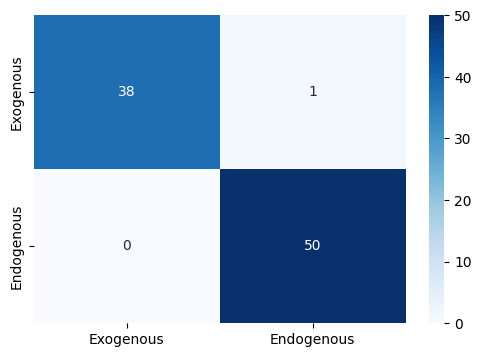

In [6]:
# plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(df['Endogenous_bool'], df['Endogenous_LLM_bool'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Exogenous', 'Endogenous'], yticklabels=['Exogenous', 'Endogenous'])

In [7]:
df.to_csv('metabolites_endo_exo_llm_gemini2.5.csv', index=False)

In [17]:
import pandas as pd

df = pd.read_csv("/data/chen/data/hmdb/metabolites.csv")

In [ ]:

# get 100 rows with 80% endogenous
df_endogenous = df[df['Endogenous']=='Yes'].sample(n=45, random_state=42)
df_non_endogenous = df[df['Endogenous']=='No'].sample(n=5, random_state=42)
df_sampled = pd.concat([df_endogenous, df_non_endogenous]).reset_index(drop=True)


In [20]:

df_sampled['Endogenous_LLM'] = df_sampled['Name'].apply(is_endogenous_compound)
df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']]

,Name,Endogenous,Endogenous_LLM
0,TG(i-16:0/a-17:0/18:0)[rac],Yes,Unclear
1,TG(i-22:0/i-18:0/a-25:0)[rac],Yes,Unclear
2,Alanylarginine,Yes,Unclear
3,"CL(18:1(9Z)/16:0/22:5(4Z,7Z,10Z,13Z,16Z)/18:1(...",Yes,Unclear
4,TG(12:0/i-20:0/14:0),Yes,Unclear
5,TG(i-17:0/i-16:0/i-15:0),Yes,Unclear
6,TG(18:0/a-21:0/i-19:0)[rac],Yes,Unclear
7,"CL(i-12:0/14:0/18:2(9Z,11Z)/18:2(9Z,11Z))",Yes,Unclear
8,S-4'-Hydroxywarfarin,Yes,Unclear
9,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))",Yes,Endogenous


In [21]:
# unclear ratio
unclear_ratio = (df_sampled['Endogenous_LLM']=='Unclear').mean()
unclear_ratio

0.88

In [13]:
# calculate accuracy, precision, recall and F1 score
df_sampled = df_sampled[df_sampled['Endogenous_LLM']!='Unclear']
df_sampled['Endogenous_bool'] = df_sampled['Endogenous'] == 'Yes'
df_sampled['Endogenous_LLM_bool'] = df_sampled['Endogenous_LLM'] == 'Endogenous'

accuracy = (df_sampled['Endogenous_bool'] == df_sampled['Endogenous_LLM_bool']).mean()
precision = (df_sampled['Endogenous_bool'] & df_sampled['Endogenous_LLM_bool']).sum() / df_sampled['Endogenous_LLM_bool'].sum()
recall = (df_sampled['Endogenous_bool'] & df_sampled['Endogenous_LLM_bool']).sum() / df_sampled['Endogenous_bool'].sum()
f1 = 2 * (precision * recall) / (precision + recall)

accuracy, precision, recall, f1

/tmp/ipykernel_2549012/1808926640.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sampled['Endogenous_bool'] = df_sampled['Endogenous'] == 'Yes'
/tmp/ipykernel_2549012/1808926640.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sampled['Endogenous_LLM_bool'] = df_sampled['Endogenous_LLM'] == 'Endogenous'


(0.8333333333333334, 0.5, 1.0, 0.6666666666666666)

<Axes: >

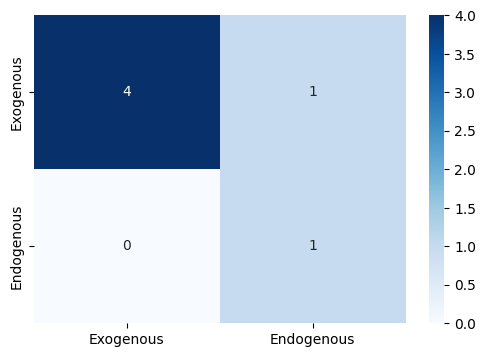

In [14]:
# plot the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(df_sampled['Endogenous_bool'], df_sampled['Endogenous_LLM_bool'])
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Exogenous', 'Endogenous'], yticklabels=['Exogenous', 'Endogenous'])

In [ ]:
df_sampled.to_csv("data/metabolites_llm_labled.csv", index=False)

In [28]:
df_temp = df_sampled[['Name', 'Endogenous', 'Endogenous_LLM']][df_sampled['Endogenous_LLM'] != 'Unclear']
df_temp['Endogenous'] = df_temp['Endogenous'].map({'Yes': 'Endogenous', 'No': 'Exogenous'})
df_temp = df_temp.rename(columns={'Endogenous': 'Ground Truth', 'Endogenous_LLM': 'LLM Prediction'})
df_temp

,Name,Ground Truth,LLM Prediction
9,"PC(18:0/22:5(4Z,7Z,10Z,13Z,16Z))",Endogenous,Endogenous
45,alpha-Linolenic acid,Exogenous,Endogenous
46,Rhodamine B,Exogenous,Exogenous
47,Gallium,Exogenous,Exogenous
48,Potassium,Exogenous,Exogenous
49,Erythrosine,Exogenous,Exogenous
